# 思考する LLM で、思考のオン・オフと思考の長さの上限を変えて正解率とコストを比べる（Qwen3 の enable_thinking と budget forcing）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/14_llm/thinking_budget.ipynb)

NLP クックブック 14-11 ／ 大規模言語モデル (LLM)

> GPU ランタイム推奨（ランタイム → ランタイムのタイプを変更 → T4 GPU）

答える前に長く考える (thinking) LLM で、思考をオンにするかオフにするか、思考を何トークンで打ち切るかによって、算数の文章題の正解率と、生成するトークン数・時間がどう変わるかを確かめ、コストに見合う設定を選びたい。

In [1]:
!pip install -q matplotlib-fontja==1.1.0

In [2]:
import re, time, unicodedata
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, StoppingCriteria, StoppingCriteriaList

torch.manual_seed(0)
# MGSM (Shi et al., 2022) の日本語: この章の「考える過程を書かせて LLM に算数の文章題を解かせる（Chain-of-Thought と self-consistency）」と同じデータ。
# 元のリポジトリ（google-research/url-nlp の mgsm/）のライセンスは CC BY 4.0（Hugging Face のデータセットカードのメタデータは CC BY-SA 4.0）
N = 40                                       # 時間の都合で 250 問のうち先頭の 40 問を使う
mgsm = load_dataset("juletxara/mgsm", "ja", split="test").select(range(N))
gold = np.array(mgsm["answer_number"], dtype=float)

# Qwen3-1.7B（Alibaba の Qwen チーム、Apache 2.0）: 1 つのモデルで思考モードと非思考モードを切り替えられる
name = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(name, padding_side="left")
BF16 = torch.cuda.get_device_capability()[0] >= 8      # bfloat16 は Ampere (A100, L4) 以降。T4 では float16 を使う
model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.bfloat16 if BF16 else torch.float16, device_map="auto").eval()
THINK_END, IM_END, EOT = tokenizer.convert_tokens_to_ids(["</think>", "<|im_end|>", "<|endoftext|>"])

# モデルカードが数学の問題に勧める指示（最後の答えを \boxed{} に書かせる）を日本語にしたもの
PROMPT = "次の問題を解いてください。ステップごとに考え、最後の答えの数値を \\boxed{{}} の中に書いてください。\n\n問題: {}"
def prompt_ids(question, thinking):
    """enable_thinking=False にすると、チャットテンプレートが空の <think></think> を先に入れて思考を飛ばさせる"""
    text = tokenizer.apply_chat_template([{"role": "user", "content": PROMPT.format(question)}], add_generation_prompt=True,
                                         tokenize=False, enable_thinking=thinking)
    return tokenizer(text, add_special_tokens=False)["input_ids"]
print(tokenizer.decode(prompt_ids(mgsm[0]["question"], thinking=False)))

class StepTimer(StoppingCriteria):
    """生成の 1 ステップごとに経過時間を記録する（止める判定はしない）"""
    def __init__(self):
        self.t0, self.times = time.time(), []
    def __call__(self, input_ids, scores, **kwargs):
        self.times.append(time.time() - self.t0)
        return torch.zeros(input_ids.shape[0], dtype=torch.bool, device=input_ids.device)

@torch.no_grad()
def generate(inputs, max_new_tokens, stop_ids, bs=40, **sampling):
    """トークン列のリストをバッチで続けて生成し、生成したトークン列のリストと、バッチごとのステップ時刻のリストを返す。
    生成したトークン列は、stop_ids のどれかが出たらそこまで（そのトークンを含む）で切る"""
    outs, timers = [], []
    for i in range(0, len(inputs), bs):
        enc = tokenizer.pad({"input_ids": inputs[i:i + bs]}, return_tensors="pt").to(model.device)
        timer = StepTimer()
        out = model.generate(**enc, max_new_tokens=max_new_tokens, eos_token_id=stop_ids, pad_token_id=tokenizer.pad_token_id,
                             stopping_criteria=StoppingCriteriaList([timer]), **sampling)[:, enc["input_ids"].shape[1]:]
        for row in out.tolist():
            ends = [j for j, t in enumerate(row) if t in stop_ids]
            outs.append(row[:ends[0] + 1] if ends else row)
        timers.append(np.array(timer.times))
    return outs, timers

def extract(text):
    """出力から答えの数値を取り出す: \\boxed{} の中 → 「答え」の後ろ → 最後に出てきた数値 の順に探す"""
    text = unicodedata.normalize("NFKC", text).replace(",", "")
    text = re.sub(r"(\d+(?:\.\d+)?)万(\d*)", lambda m: str(round(float(m.group(1)) * 10000) + int(m.group(2) or 0)), text)   # 「3万5000」→ 35000
    for pattern in [r"\\boxed\{[^\d\-]*(-?\d+(?:\.\d+)?)", r"答え[はが]?\s*[:：]?[^\d\-\n]*(-?\d+(?:\.\d+)?)"]:
        found = re.findall(pattern, text)
        if found:
            return float(found[-1])
    found = re.findall(r"-?\d+(?:\.\d+)?", text)
    return float(found[-1]) if found else np.nan

<|im_start|>user
次の問題を解いてください。ステップごとに考え、最後の答えの数値を \boxed{} の中に書いてください。

問題: ジャネットのアヒルは1日に16個の卵を生みます。ジャネットは毎朝朝食の一環で3個を消費し、毎日4個使って友達向けにマフィンを焼きます。残りを市場で1個あたり2ドルの価格で売ります。彼女は毎日市場でいくら手に入れていますか？<|im_end|>
<|im_start|>assistant
<think>

</think>




In [3]:
# 1. 思考オフ: 答えの文章（途中の計算を含む）をそのまま生成させる。サンプリングの設定はモデルカードが非思考モードに勧める値
#    Colab の T4 で 1〜2 分程度（検証の GPU での時間の約 2.5 倍として見積もった目安。T4 では測っていない）
ANSWER_MAX = 768                 # 答えの文章の上限（思考オフと、思考のあとの答えで共通）
NOTHINK_SAMPLING = dict(do_sample=True, temperature=0.7, top_p=0.8, top_k=20)
off_tokens, off_timers = generate([prompt_ids(q, False) for q in mgsm["question"]], ANSWER_MAX, [IM_END, EOT], **NOTHINK_SAMPLING)
off_text = [tokenizer.decode(t, skip_special_tokens=True) for t in off_tokens]

# 2. 思考オン: </think> が出るまで、最大 T_MAX トークンまで考えさせる。設定はモデルカードが思考モードに勧める値（generation_config の既定値と同じ）
#    Colab の T4 で 2〜3 分程度（同じく見積もり）
T_MAX = 1024
THINK_SAMPLING = dict(do_sample=True, temperature=0.6, top_p=0.95, top_k=20)
think_prompts = [prompt_ids(q, True) for q in mgsm["question"]]
thoughts, think_timers = generate(think_prompts, T_MAX, [THINK_END, IM_END, EOT], **THINK_SAMPLING)
think_len = np.array([len(t) for t in thoughts])
finished = np.array([t[-1] == THINK_END for t in thoughts])
print(f"思考を自分で終えた問題: {finished.sum()} / {N}、思考の長さ（トークン）の分位点 10/50/90%:",
      np.percentile(think_len[finished], [10, 50, 90]).round().tolist())
# 問題は日本語だが、思考は何語で書かれるか: 思考の中の文字（かな・漢字・英字など）のうち ASCII の英字の割合
latin = [sum(c.isascii() and c.isalpha() for c in t) / max(1, sum(c.isalpha() for c in t)) for t in tokenizer.batch_decode(thoughts)]
print("思考の文字に占める英字の割合: 中央値", round(float(np.median(latin)), 3), "最小", round(min(latin), 3))
print(f"GPU メモリ最大 {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

思考を自分で終えた問題: 24 / 40、思考の長さ（トークン）の分位点 10/50/90%: [366.0, 482.0, 760.0]
思考の文字に占める英字の割合: 中央値 0.989 最小 0.885
GPU メモリ最大 9.4 GB


In [4]:
# 3. budget forcing: 思考を B トークンで打ち切り、「時間がないので今までの思考で答える」という文と </think> を足して答えを書かせる。
#    打ち切りの文は Qwen3 の技術報告にあるもの。サンプリングで作った思考を先頭から B トークンで切るのは、
#    初めから B トークンの上限を付けて生成するのと同じなので、思考は 1 回だけ生成し、上限ごとに答えの部分だけを生成する
#    4 回の答えの生成で、Colab の T4 で 8〜10 分程度（同じく見積もり）
STOP_THINKING = tokenizer("\n\nConsidering the limited time by the user, I have to give the solution based on the thinking directly now.\n</think>\n\n",
                          add_special_tokens=False)["input_ids"]
NEWLINES = tokenizer("\n\n", add_special_tokens=False)["input_ids"]
BUDGETS = [128, 256, 512, 1024]

def batch_seconds(timers, steps):
    """各バッチが steps ステップ目（それより前に全部終わったならその時点）までにかかった秒数の合計"""
    return sum(t[min(steps, len(t)) - 1] for t in timers)

def cut_thought(t, B):
    """思考を B トークンで切る。B 以内に自分で終えたものはそのまま。</think> を出さずに <|im_end|> などで止まった思考は、その記号を落とす"""
    if len(t) <= B and t[-1] == THINK_END:
        return t
    t = t[:B]
    return t[:-1] if t and t[-1] in (IM_END, EOT) else t

results, answers_text, preds = {}, {}, {}
off_pred = np.array([extract(t) for t in off_text])
results["思考オフ"] = {"正解率": np.mean(off_pred == gold), "思考トークン（平均）": 0, "回答トークン（平均）": np.mean([len(t) for t in off_tokens]),
                    "思考を打ち切った割合": 0.0, "回答が上限で切れた割合": np.mean([t[-1] not in (IM_END, EOT) for t in off_tokens]),
                    "1 問あたりの秒数": batch_seconds(off_timers, 10**9) / N}
for B in BUDGETS:
    cut = [cut_thought(t, B) for t in thoughts]
    forced = np.array([not (c and c[-1] == THINK_END) for c in cut])
    inputs = [p + c + (STOP_THINKING if f else NEWLINES) for p, c, f in zip(think_prompts, cut, forced)]
    ans_tokens, ans_timers = generate(inputs, ANSWER_MAX, [IM_END, EOT], **THINK_SAMPLING)
    answers_text[B] = [tokenizer.decode(t, skip_special_tokens=True) for t in ans_tokens]
    pred = np.array([extract(t) for t in answers_text[B]])
    label = f"思考オン（上限 {B}）"
    preds[label] = pred
    results[label] = {"正解率": np.mean(pred == gold), "思考トークン（平均）": np.mean([len(c) for c in cut]),
                      "回答トークン（平均）": np.mean([len(t) for t in ans_tokens]), "思考を打ち切った割合": forced.mean(),
                      "回答が上限で切れた割合": np.mean([t[-1] not in (IM_END, EOT) for t in ans_tokens]),
                      "1 問あたりの秒数": (batch_seconds(think_timers, B) + batch_seconds(ans_timers, 10**9)) / N}
    results[label]["correct"] = pred == gold
results["思考オフ"]["correct"] = off_pred == gold
preds = {"思考オフ": off_pred, **preds}

table = pd.DataFrame({k: {m: v for m, v in r.items() if m != "correct"} for k, r in results.items()}).T
table["合計トークン（平均）"] = table["思考トークン（平均）"] + table["回答トークン（平均）"]
table["正解 1 問あたりのトークン"] = table["合計トークン（平均）"] / table["正解率"]
pd.set_option("display.width", 200)
print(table.round(3).to_string())
print(f"GPU メモリ最大 {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

                 正解率  思考トークン（平均）  回答トークン（平均）  思考を打ち切った割合  回答が上限で切れた割合  1 問あたりの秒数  合計トークン（平均）  正解 1 問あたりのトークン
思考オフ           0.475       0.000     325.750       0.000        0.000      0.811     325.750         685.789
思考オン（上限 128）   0.600     128.000     278.225       1.000        0.000      1.234     406.225         677.042
思考オン（上限 256）   0.650     256.000     260.575       1.000        0.025      1.618     516.575         794.731
思考オン（上限 512）   0.650     480.475     219.800       0.625        0.000      1.664     700.275        1077.346
思考オン（上限 1024）  0.625     729.175     251.400       0.400        0.025      3.800     980.575        1568.920
GPU メモリ最大 13.2 GB


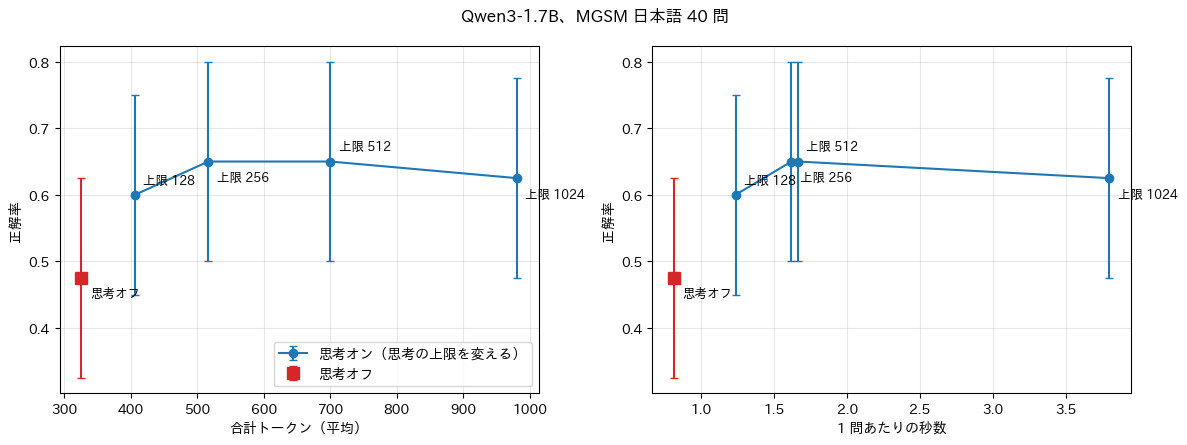

In [5]:
# 正解率とコスト（トークン数・時間）の関係を図にする。縦の線は正解率の 95% 信頼区間（ブートストラップ）
import matplotlib.pyplot as plt
import matplotlib_fontja  # import するだけで日本語のフォントになる

rng = np.random.default_rng(0)
idx = rng.integers(0, N, (2000, N))
acc = table["正解率"].to_numpy()
ci = np.array([np.percentile(r["correct"][idx].mean(axis=1), [2.5, 97.5]) for r in results.values()])
err = np.abs(ci - acc[:, None]).T
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ["合計トークン（平均）", "1 問あたりの秒数"]):
    x = table[col].to_numpy()
    ax.errorbar(x[1:], acc[1:], yerr=err[:, 1:], fmt="o-", capsize=3, label="思考オン（思考の上限を変える）")
    ax.errorbar(x[:1], acc[:1], yerr=err[:, :1], fmt="s", color="tab:red", capsize=3, markersize=8, label="思考オフ")
    for i, label in enumerate(table.index):
        ax.annotate(label.replace("思考オン（", "").rstrip("）"), (x[i], acc[i]), textcoords="offset points",
                    xytext=(6, 8 if i % 2 else -14), fontsize=9)
    ax.set_xlabel(col); ax.set_ylabel("正解率"); ax.grid(alpha=0.3)
axes[0].legend(loc="lower right")
plt.suptitle(f"Qwen3-1.7B、MGSM 日本語 {N} 問")
plt.tight_layout(); plt.show()

In [6]:
# 差は偶然の範囲か: 同じ問題で比べる対応のあるブートストラップで、正解率の差の 95% 信頼区間を求める
rng = np.random.default_rng(0)
def diff_ci(a, b, n_boot=2000):
    x, y = results[a]["correct"].astype(float), results[b]["correct"].astype(float)
    idx = rng.integers(0, N, (n_boot, N))
    d = x[idx].mean(axis=1) - y[idx].mean(axis=1)
    print(f"{a} − {b}: {(x.mean() - y.mean()) * 100:+5.1f} ポイント [{np.percentile(d, 2.5) * 100:+5.1f}, {np.percentile(d, 97.5) * 100:+5.1f}]")

labels = list(results)
diff_ci(labels[1], "思考オフ")
diff_ci(labels[-1], "思考オフ")
for a, b in zip(labels[2:], labels[1:-1]):
    diff_ci(a, b)

思考オン（上限 128） − 思考オフ: +12.5 ポイント [ +0.0, +25.0]
思考オン（上限 1024） − 思考オフ: +15.0 ポイント [ +0.0, +30.0]
思考オン（上限 256） − 思考オン（上限 128）:  +5.0 ポイント [ -5.0, +15.0]
思考オン（上限 512） − 思考オン（上限 256）:  +0.0 ポイント [ -7.5,  +7.5]
思考オン（上限 1024） − 思考オン（上限 512）:  -2.5 ポイント [ -7.5,  +0.0]


In [7]:
# 思考の中身の例: 上限 T_MAX で正解した問題のうち思考が最も短かったもの（自分で終えた）と、T_MAX トークンでも終わらなかった問題
def show(i, head_budget=None):
    t = tokenizer.decode(thoughts[i])
    status = "自分で終えた" if finished[i] else f"{T_MAX} トークンで打ち切った"
    print(f"=== 問題 {i}（正解 {gold[i]:g}）: {mgsm[i]['question'][:70]}…")
    print(f"--- 思考（{len(thoughts[i])} トークン、{status}）の先頭:\n{t[:500]}\n  …\n--- 思考の末尾:\n{t[-400:]}")
    print("--- 思考の上限ごとに取り出した答え:", {B: extract(answers_text[B][i]) for B in BUDGETS})
    if head_budget:
        print(f"--- 上限 {head_budget} のとき（思考を打ち切った）の答えの先頭:\n{answers_text[head_budget][i][:300]}\n  …")
    print(f"--- 上限 {T_MAX} のときの答えの末尾:\n{answers_text[T_MAX][i][-200:]}\n")

ok = results[f"思考オン（上限 {T_MAX}）"]["correct"]
show(int(np.argmin(np.where(finished & ok, think_len, 10**9))))
show(int(np.flatnonzero(~finished)[0]), head_budget=BUDGETS[0])

# MGSM の日本語訳には、英語の原文と答えが合わない問題がある。問題 18 は原文が "How many dozens of eggs will she eat in 4 weeks?"（答え 7）だが、
# 訳では「卵を何個食べることになりますか」と「ダース」が落ちている
print(f"問題 18（正解 {gold[18]:g}）: {mgsm[18]['question']}")
print("取り出した答え:", {k: float(v[18]) for k, v in preds.items()})

=== 問題 33（正解 70）: グレッチェンは110枚のコインを持っています。金のコインは銀のコインよりも30枚多いです。グレッチェンは金のコインを何枚持っていますか？…
--- 思考（358 トークン、自分で終えた）の先頭:
<think>
Okay, let's see. Gretch has 110 coins in total. The problem says that the number of gold coins is 30 more than the number of silver coins. I need to find out how many gold coins she has.

Hmm, let me break this down. Let's denote the number of silver coins as S. Then, the number of gold coins would be S plus 30, right? So, G = S + 30.

But we also know that the total number of coins is 110. So, S + G = 110. Substituting the first equation into the second, we get S + (S + 30) = 110. Let m
  …
--- 思考の末尾:
 subtract 30 from both sides: 2S = 80. Then divide both sides by 2: S = 40. So, the number of silver coins is 40. Then, the number of gold coins would be 40 + 30 = 70. 

Wait, let me verify. If there are 40 silver coins and 70 gold coins, that's 40 + 70 = 110 coins. And the gold coins are 30 more than the silver ones (70 - 40 = 30). That checks out. So, the answer s

- Qwen3 は 1 つのモデルで思考モードと非思考モードを切り替えられる（モデルカード）。`apply_chat_template` に `enable_thinking=False` を渡すと、最初の出力にあるとおり、テンプレートが空の `<think>\n\n</think>` をアシスタントの発話の先頭に入れ、思考を飛ばして答えから書かせる。思考モードでは `</think>`（トークン ID は `THINK_END`）までが思考である。問題文は日本語だが、思考の文字の 98.9%（中央値）は英字で、思考は英語で書かれた（答えは、例のように日本語で書かれた）。思考を 1024 トークン以内に自分で終えたのは 40 問中 24 問で、その長さの中央値は 482 トークンだった。
- 結果（先頭の 40 問、T4 と同じ float16 で実行）: 思考オフの正解率 47.5% に対し、思考オンは上限 128 トークンで 60.0%、上限 256・512 で 65.0%、上限 1024 で 62.5% だった。思考オフとの差は、上限 128 で +12.5 ポイント [0.0, +25.0]、上限 1024 で +15.0 ポイント [0.0, +30.0] で、信頼区間の下限がちょうど 0 なので、思考の効果ははっきりしたとまでは言えない。上限どうしの差（−2.5〜+5.0 ポイント）はどれも信頼区間が 0 を含み、この件数では区別できない。正解 1 問あたりのトークン数は、思考オフ 686、上限 128 で 677、上限 1024 で 1,569 で、この設定では、思考オフとの差のほとんどは短い思考で得られ、それより長く考えさせても正解率は上がらず、コストだけが増えた（上限どうしの差は区別できない範囲）。
- budget forcing は Muennighoff et al. (2025) の s1 が提案した方法で、思考の最大の長さは思考の終わりの記号（と「Final Answer:」）を足して打ち切り、最小の長さは終わりの記号を出させずに「Wait」を足して延ばす（ここでは打ち切りだけを試した）。打ち切りの文は Qwen3 の技術報告 (Qwen Team, 2025) にあるもので、報告では「この能力は明示的に学習させたものではなく、思考モードと非思考モードを 1 つのモデルに統合した学習から自然に現れた」としている（報告の文字列は `</think>.` と後ろにピリオドがあるが、ここでは付けていない）。思考を打ち切ったときは、答えの部分で計算を書き直す（2 つ目の例の上限 128 の答えは、途中の計算を書いたうえで 16 個を「4 セット」と数え違えて 32 と答えた）。回答のトークン数は、上限 128 では平均 278 と、思考を自分で終えた問題が多い上限 512（220）より長く、思考を削った分だけコストが減るわけではない。
- 1 つ目の例（問題 33）は 358 トークンで思考を自分で終え、最後に答えを検算していた。2 つ目の例（問題 5）は 1024 トークンでも思考が終わらず、末尾では 2 個・3 個・4 個の場合の金額を順に確かめ直していた。この問題は上限 256 以上では正解 (64) だったが、上限 128 では 32 と答えた。モデルカードは出力の長さを 32,768 トークンまで許すことを勧めており、ここでの上限 1024 はそれよりずっと短い。思考を最後まで続けさせたときの正解率は測っていない。
- 時間は、40 問を 1 つのバッチで生成したときの 1 問あたりの平均で、検証に使った GPU（float16、T4 ではもっとかかる）での値である。バッチの中で最も長い出力が終わるまで待つので、トークン数に比例しない（上限 256 → 512 で合計トークンは 36% 増えたが、時間は 3% 増にとどまった）。上限ごとの時間は、1 回の思考の生成で B ステップ目までにかかった時間と、答えの生成の時間の和である（思考を先頭から B トークンで切るのは、初めから上限 B で生成するのと同じなので、思考の生成は 1 回で済ませた）。
- サンプリングの設定はモデルカードの推奨に従い、思考モードは温度 0.6・top_p 0.95・top_k 20、非思考モードは温度 0.7・top_p 0.8・top_k 20 にした（思考モードで貪欲法を使うと性能が下がり、同じ文を繰り返すことがあるとモデルカードに書かれている）。思考のオンとオフでは設定も違う。乱数の種は 1 つしか試しておらず、種を変えたときのばらつきは確かめていない。答えの上限 (768) で切れた出力は、どの条件でも 40 問中 1 問以下だった。
- この章の「考える過程を書かせて LLM に算数の文章題を解かせる（Chain-of-Thought と self-consistency）」と同じ MGSM の日本語を使っているが、モデル（そちらは sarashina2.2-1b-instruct）、問題数、指示文が違うので、正解率は直接比べられない。Qwen3 の技術報告によると、大きなモデルは長い CoT のデータでの学習と強化学習で思考を身につけ、1.7B などの小さなモデルはそれを蒸留して作られた。self-consistency が複数の答えを並列に作るのに対して、思考は 1 本の推論を長くする。API の LLM でも思考の量を指定できる（LLM の API の章の「Gemini API を呼び出す（無料枠）」の注意書きを参照）。MGSM は公開から時間がたっており、Qwen3 の技術報告でも事前学習モデルの評価に使われている。学習データに含まれていないかは確かめられない。また、日本語訳には英語の原文と答えが合わない問題がある。問題 18 は原文が "How many dozens of eggs will she eat in 4 weeks?"（答え 7）だが、訳では「ダース」が落ちており、日本語の問題文に対して正しい 84 を答えても不正解になる（最後の出力のとおり、どの条件でも 84 と答えた）。そのため、どの条件の正解率も 40 問中 39 問 (97.5%) が上限である。
- ライセンスは、Qwen3-1.7B が Apache 2.0、MGSM が元のリポジトリの mgsm/LICENSE では CC BY 4.0、Hugging Face のデータセットカードのメタデータでは CC BY-SA 4.0。モデルのダウンロードは約 4 GB。GPU メモリの最大は 13.2 GB（float16、答えの生成のとき）で、T4 の 15 GB に近い。`T_MAX` や問題数を増やすときは `generate` の `bs` を下げる。